In [1]:
%load_ext autoreload
%autoreload 2

In [2]:

import os
import torch.backends.cudnn as cudnn
import torch
import torchvision
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
from datetime import datetime 
import pdb
import yaml
import sys
import glob
import shutil
import tqdm
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import seaborn as sns
from scipy.stats import ttest_ind, spearmanr

sys.path.append('../../MARS')


In [29]:
#pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/val_df.csv').columns
pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/test_df.csv').columns

Index(['filepath', 'filename', 'filename_header', 'fullfile', 'patient_age',
       'patient_sex', 'patient_weight', 'smoking_status', 'accession',
       'study_uid', 'series_uid', 'scan_time', 'modality', 'matrix_size_1',
       'matrix_size_2', 'matrix_size_3', 'pixel_size_1', 'pixel_size_2',
       'pixel_size_3', 'pixel_size_3_str', 'slice_thickness',
       'description_series', 'description_study', 'admitting_diagnoses',
       'protocol_name', 'image_comments', 'body_part', 'manufacturer',
       'manufacturer_model', 'software', 'convolution_kernel',
       'factor_bqml2suv', 'xray_tube_current', 'kvp', 'contrast_agent',
       'patient_position', 'imaging_plane', 'image_orientation',
       'patient_history', 'img_max', 'img_min', 'img_mean', 'img_std',
       'img_sum', 'img_count_nonzeros', 'img_mean_nonzeros',
       'img_std_nonzeros', 'img_sum_nonzeros', 'reconstruction', 'corrections',
       'pixel_unit', 'frame_duration', 'tracer', 'tracer_injection_time',
       'tra

In [31]:
#pred_df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/val/pred_val_mipview_aggregate.csv')
pred_df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/test/pred_test_mipview_aggregate.csv')

pred_df = pred_df.iloc[:, :64]
pred_df['error'] = pred_df['PET_jco'] - pred_df['probs_mean']
pred_df['error_abs'] = np.abs(pred_df['error'])

In [32]:
pred_df['patient_age'] = pred_df['patient_age'].apply(lambda x: int(x.split('Y')[0]) if isinstance(x, str) else x)
# one-hot encode stuff
pred_df = pd.get_dummies(pred_df, columns=['patient_sex', 'description_series', 'admitting_diagnoses', 'protocol_name', 'body_part', 'manufacturer',
                                 'manufacturer_model', 'software', 'patient_position', 'reconstruction',
                                 'corrections', ], drop_first=True)

In [33]:
# extract float from string
# replace All-pass with 0.00
pred_df['convolution_kernel'] = pred_df['convolution_kernel'].replace('All-pass', '0.00')
pred_df['convolution_kernel'] = pred_df['convolution_kernel'].str.extract('(\d+.\d+)').astype(float)

In [34]:
# convert injection time from float to some time object that can be added or subtracted from acquisition time
def hhmmss_to_seconds(t):
    t = int(t)
    h = int(t // 10000)
    m = int((t % 10000) // 100)
    s = t % 100
    return h * 3600 + m * 60 + s

pred_df['tracer_injection_time_seconds'] = pred_df['tracer_injection_time'].apply(hhmmss_to_seconds)
pred_df['scan_time_seconds'] = pred_df['scan_time'].apply(hhmmss_to_seconds)
pred_df['uptake_time_seconds'] = pred_df['scan_time_seconds'] - pred_df['tracer_injection_time_seconds']

In [35]:
# create a version of pred_df where probabilities are averaged across the model_number, and all other columns are the same across the different model_number entries for the same patient/scan
# agg probs using mean, everything else with first, but don't make the code very long

pred_df_agg = pred_df.groupby(['filename']).agg({'probs_mean': 'mean', 'probs_max': 'mean', 'error': 'mean', 'error_abs': 'mean'}).reset_index()

# create second df with all the other columns, but drop the model_number and probs columns, and drop duplicates
pred_df_other = pred_df.drop(columns=['model_number', 'probs_mean', 'probs_max', 'error', 'error_abs']).drop_duplicates(subset=['filename'])

# merge the two dfs on filename
pred_df_final = pd.merge(pred_df_other, pred_df_agg, on='filename')

pred_df_final

,filepath,filename,filename_header,fullfile,patient_age,patient_weight,smoking_status,accession,study_uid,series_uid,...,corrections_NORM|DTIM|ATTN|SCAT|DECY|RAN,corrections_NORM|DTIM|ATTN|SCAT|RADL|DECY,corrections_RAN|DTIM|NORM|ATTN|SCAT|DECY,tracer_injection_time_seconds,scan_time_seconds,uptake_time_seconds,probs_mean,probs_max,error,error_abs
0,22780432,22780432_pt_2.h5,22780432_pt_2.pkl,22780432/22780432_pt_2.h5,68.0,124.286000,UNKNOWN,22780432,1.2.840.114350.2.232.2.798268.2.512994687.1,1.3.12.2.1107.5.1.4.60051.30000021070214034336...,...,True,False,False,51180,55084,3904,0.055823,0.092942,-0.055823,0.055823
1,18096721,18096721_pt_0.h5,18096721_pt_0.pkl,18096721/18096721_pt_0.h5,75.0,83.007414,UNKNOWN,18096721,1.2.840.114350.2.232.2.798268.2.336492015.1,1.3.12.2.1107.5.1.4.11052.30000019080612554450...,...,True,False,False,29340,32141,2801,0.310200,0.456135,0.689800,0.689800
2,17352726,17352726_pt_0.h5,17352726_pt_0.pkl,17352726/17352726_pt_0.h5,69.0,66.224494,UNKNOWN,17352726,1.2.840.114350.2.232.2.798268.2.312201279.1,1.3.12.2.1107.5.1.4.11052.30000019041213150840...,...,True,False,False,41100,45212,4112,0.949308,0.999419,0.050692,0.050692
3,40663300,40663300_pt_2.h5,40663300_pt_2.pkl,40663300/40663300_pt_2.h5,67.0,63.504000,UNKNOWN,40663300,1.2.840.114350.2.232.2.798268.2.827647775.1,1.3.12.2.1107.5.1.4.10119.30000024020315441791...,...,True,False,False,56520,64215,7695,0.997857,0.999625,0.002143,0.002143
4,5704635,5704635_pt_0.h5,5704635_pt_0.pkl,5704635/5704635_pt_0.h5,65.0,74.910000,NO,5704635,1.2.840.113696.323972.500.1711319.20110310151557,1.3.12.2.1107.5.1.4.44843.30000011031913355385...,...,False,False,True,50400,54190,3790,0.855680,0.929192,0.144320,0.144320
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
587,13489932,13489932_pt_0.h5,13489932_pt_0.pkl,13489932/13489932_pt_0.h5,63.0,114.305292,UNKNOWN,13489932,1.2.840.114350.2.232.2.798268.2.186662290.1,1.3.12.2.1107.5.1.4.11052.30000017063012474995...,...,True,False,False,39600,42774,3174,0.273331,0.429276,-0.273331,0.273331
588,33193253,33193253_pt_0.h5,33193253_pt_0.pkl,33193253/33193253_pt_0.h5,42.0,112.000000,NaN,33193253,1.2.840.113619.2.55.3.2550794926.59.1673559481...,1.2.840.113619.2.131.2550794926.1675258179.568344,...,False,False,False,27360,30627,3267,0.039885,0.076549,-0.039885,0.039885
589,5547467,5547467_pt_0.h5,5547467_pt_0.pkl,5547467/5547467_pt_0.h5,71.0,99.880000,NO,5547467,1.2.840.113696.323972.500.1561265.2010112314061,1.3.12.2.1107.5.1.4.44843.30000011010712191609...,...,False,False,True,41700,45159,3459,0.003882,0.006696,-0.003882,0.003882
590,15358448,15358448_pt_0.h5,15358448_pt_0.pkl,15358448/15358448_pt_0.h5,79.0,68.038864,UNKNOWN,15358448,1.2.840.114350.2.232.2.798268.2.243093907.1,1.3.12.2.1107.5.1.4.11052.30000018060213321147...,...,True,False,False,40080,43978,3898,0.400323,0.581445,-0.400323,0.400323


In [9]:
pred_df.columns[:50]

Index(['filepath', 'filename', 'filename_header', 'fullfile', 'patient_age',
       'patient_weight', 'smoking_status', 'accession', 'study_uid',
       'series_uid', 'scan_time', 'modality', 'matrix_size_1', 'matrix_size_2',
       'matrix_size_3', 'pixel_size_1', 'pixel_size_2', 'pixel_size_3',
       'pixel_size_3_str', 'slice_thickness', 'description_study',
       'image_comments', 'convolution_kernel', 'factor_bqml2suv',
       'xray_tube_current', 'kvp', 'contrast_agent', 'imaging_plane',
       'image_orientation', 'patient_history', 'img_max', 'img_min',
       'img_mean', 'img_std', 'img_sum', 'img_count_nonzeros',
       'img_mean_nonzeros', 'img_std_nonzeros', 'img_sum_nonzeros',
       'pixel_unit', 'frame_duration', 'tracer', 'tracer_injection_time',
       'tracer_dose', 'tracer_halflife', 'image_filter', 'contrast_route',
       'axial_fov', 'PET_jco', 'PET_imwg'],
      dtype='object')

In [13]:
feature_cols = [col for col in pred_df.columns if col not in ['filepath', 'filename', 'filename_header', 'fullfile', 'study_uid', 'series_uid', 'accession', 'smoking_status', 
                                                              'modality', 'pixel_size_3_str', 'description_study', 'image_comments',
                                                              'xray_tube_current', 'kvp', 'contrast_agent', 'imaging_plane',
                                                              'image_orientation', 'patient_history', 'pixel_unit', 'tracer',
                                                              'image_filter', 'contrast_route', 'img_min',
                                                              'uptake_time_seconds', 'tracer_dose',
                                                              'PET_jco', 'PET_imwg', 'model_number',
                                                              'probs_mean', 'probs_max',
                                                              'error', 'error_abs', 'PET_jco']]

<Axes: xlabel='uptake_time_seconds', ylabel='Count'>

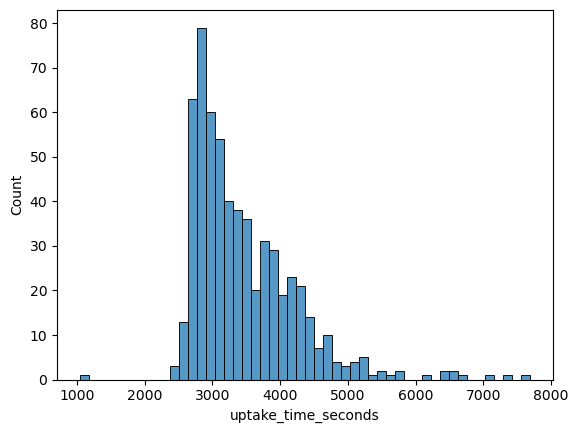

In [36]:
# what is the distribution of uptake time?
sns.histplot(pred_df_final['uptake_time_seconds'], bins=50)

In [56]:
pred_df_final['tracer_dose'] * (0.5)**((pred_df_final['uptake_time_seconds']) / pred_df_final['tracer_halflife'])

0      3.876340e+08
1      4.188151e+08
2      3.722800e+08
3      2.663614e+08
4      3.749318e+08
           ...     
587    4.252119e+08
588    3.856708e+08
589    3.812811e+08
590    3.864059e+08
591    4.477027e+08
Length: 592, dtype: float64

SignificanceResult(statistic=np.float64(0.06480854558550611), pvalue=np.float64(0.357086019538158))
SignificanceResult(statistic=np.float64(0.14759238881367007), pvalue=np.float64(0.0036137673827756475))
SignificanceResult(statistic=np.float64(-0.1193461390827115), pvalue=np.float64(0.018843115937119275))


<Axes: xlabel='dose_curr_mbeq', ylabel='probs_mean'>

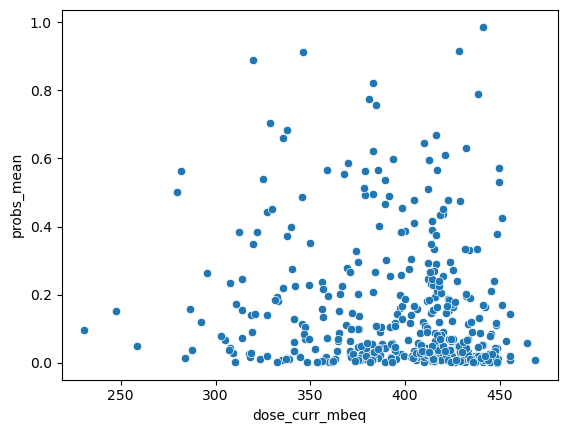

In [59]:
# what is the relationship between uptake time and the model's predicted probability?
#sns.scatterplot(x=pred_df_final['uptake_time_seconds'], y=pred_df_final['probs_mean'])

# what is relationship between uptake time and probability - label
#sns.scatterplot(x=pred_df_final['uptake_time_seconds'], y=pred_df_final['probs_mean'] - pred_df_final['PET_jco'], hue=pred_df_final['PET_jco'])

pred_df_final['dose_curr_mbeq'] = pred_df_final['tracer_dose']/1000000.0 * (0.5)**((pred_df_final['uptake_time_seconds']) / pred_df_final['tracer_halflife'])

tmp_df = pred_df_final[pred_df_final['uptake_time_seconds'] >= 2000]

# among cases with PET_jco == 1, what is the spearman correlation between uptake time and predicted probability, along with p value?
print(spearmanr(tmp_df[tmp_df['PET_jco'] == 1]['uptake_time_seconds'], tmp_df[tmp_df['PET_jco'] == 1]['probs_mean']))

# among cases with PET_jco == 0, what is the spearman correlation between uptake time and predicted probability, along with p value?
#print(spearmanr(tmp_df[tmp_df['PET_jco'] == 0]['uptake_time_seconds'], tmp_df[tmp_df['PET_jco'] == 0]['probs_mean']))
print(spearmanr(tmp_df[tmp_df['PET_jco'] == 0]['uptake_time_seconds'], tmp_df[tmp_df['PET_jco'] == 0]['probs_mean']))

print(spearmanr(tmp_df[tmp_df['PET_jco'] == 0]['dose_curr_mbeq'], tmp_df[tmp_df['PET_jco'] == 0]['probs_mean']))

# plot uptake time against predicted probability, but only for label = 0
#sns.scatterplot(x=tmp_df[tmp_df['PET_jco'] == 0]['uptake_time_seconds'], y=tmp_df[tmp_df['PET_jco'] == 0]['probs_mean'])
sns.scatterplot(x=tmp_df[tmp_df['PET_jco'] == 0]['dose_curr_mbeq'], y=tmp_df[tmp_df['PET_jco'] == 0]['probs_mean'])

In [60]:
pred_df_final.sort_values('uptake_time_seconds', ascending=False)

,filepath,filename,filename_header,fullfile,patient_age,patient_weight,smoking_status,accession,study_uid,series_uid,...,corrections_NORM|DTIM|ATTN|SCAT|RADL|DECY,corrections_RAN|DTIM|NORM|ATTN|SCAT|DECY,tracer_injection_time_seconds,scan_time_seconds,uptake_time_seconds,probs_mean,probs_max,error,error_abs,dose_curr_mbeq
3,40663300,40663300_pt_2.h5,40663300_pt_2.pkl,40663300/40663300_pt_2.h5,67.0,63.504000,UNKNOWN,40663300,1.2.840.114350.2.232.2.798268.2.827647775.1,1.3.12.2.1107.5.1.4.10119.30000024020315441791...,...,False,False,56520,64215,7695,0.997857,0.999625,0.002143,0.002143,266.361371
168,14068858,14068858_pt_0.h5,14068858_pt_0.pkl,14068858/14068858_pt_0.h5,45.0,100.000000,NaN,14068858,1.2.840.113619.2.55.3.2567586088.689.150763590...,1.2.840.113619.2.131.2567586088.1508162800.484547,...,False,False,29100,36448,7348,0.996273,0.999999,0.003727,0.003727,224.792496
557,8139510,8139510_pt_0.h5,8139510_pt_0.pkl,8139510/8139510_pt_0.h5,66.0,82.553822,UNKNOWN,8139510,1.2.840.114350.2.232.2.798268.2.24381759.1,1.3.12.2.1107.5.1.4.11052.30000013022814105182...,...,False,False,40200,47244,7044,0.073204,0.109807,0.926796,0.926796,249.638001
413,16611959,16611959_pt_0.h5,16611959_pt_0.pkl,16611959/16611959_pt_0.h5,52.0,73.028381,UNKNOWN,16611959,1.2.840.114350.2.232.2.798268.2.284307523.1,1.3.12.2.1107.5.1.4.11052.30000018121414150619...,...,False,False,50280,57015,6735,0.048659,0.091431,-0.048659,0.048659,258.618146
63,40344314,40344314_pt_2.h5,40344314_pt_2.pkl,40344314/40344314_pt_2.h5,67.0,82.555000,UNKNOWN,40344314,1.2.840.114350.2.232.2.798268.2.796484687.1,1.3.12.2.1107.5.1.4.10119.30000024020114003552...,...,False,False,63900,70442,6542,0.500151,0.663193,-0.500151,0.500151,279.723170
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,9785456,9785456_pt_0.h5,9785456_pt_0.pkl,9785456/9785456_pt_0.h5,68.0,64.410125,UNKNOWN,9785456,1.2.840.114350.2.232.2.798268.2.80492782.1,1.3.12.2.1107.5.1.4.11052.30000015030714125456...,...,False,False,46740,49252,2512,0.002917,0.004956,-0.002917,0.002917,441.122565
271,19956067,19956067_pt_0.h5,19956067_pt_0.pkl,19956067/19956067_pt_0.h5,71.0,63.502940,UNKNOWN,19956067,1.2.840.114350.2.232.2.798268.2.352589539.1,1.3.12.2.1107.5.1.4.11052.30000020061712550885...,...,False,False,43980,46470,2490,0.057773,0.103991,-0.057773,0.057773,464.067290
324,15285251,15285251_pt_0.h5,15285251_pt_0.pkl,15285251/15285251_pt_0.h5,48.0,113.398107,UNKNOWN,15285251,1.2.840.114350.2.232.2.798268.2.244178194.1,1.3.12.2.1107.5.1.4.11052.30000018051014342801...,...,False,False,56040,58515,2475,0.073723,0.110486,0.926277,0.926277,440.847554
254,20611113,20611113_pt_0.h5,20611113_pt_0.pkl,20611113/20611113_pt_0.h5,45.0,56.699053,UNKNOWN,20611113,1.2.840.114350.2.232.2.798268.2.430885865.1,1.3.12.2.1107.5.1.4.11052.30000020092112490673...,...,False,False,55560,58022,2462,0.011713,0.019921,-0.011713,0.011713,435.169144
